In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids
from sklearn.decomposition import PCA

from cluster_weather_years.functions import build_df, plot_clim_per_cluster

from cluster_weather_years.constants import BASE_OUTPUT, YEAR_COL
# from sa_settings import MATCH_COUNTRIES

In [2]:
NUM_CLUSTERS = 30  # Number of clusters to create
MATCH_COUNTRIES = "NL"  # Countries to cluster on

# Build NL dataframe
# build df
DF_PROD_DEMAND_FNAME = os.path.join(
    BASE_OUTPUT, "dataframes/df_prod_demand_daily_multi_country_WRONG_CAPACITIES.csv"
)
SA_OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

df_daily = pd.read_csv(DF_PROD_DEMAND_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year > 2014 and Hydrological_year < 2044")
df_daily = df_daily.set_index(["model", "Date"])

vars_to_match = (
    [f"{country}_OFF_prod" for country in MATCH_COUNTRIES]
    + [f"{country}_ON_prod" for country in MATCH_COUNTRIES]
    + [f"{country}_SOLAR_prod" for country in MATCH_COUNTRIES]
    + [f"{country}_Demand" for country in MATCH_COUNTRIES]
)

# 1. Compute mean and standard deviation per year w.r.t. climatology

In [3]:
clim_means = df_daily.loc[
    :, [c for c in df_daily.columns if c != "Hydrological_year"]
].mean(axis=0)

yearly_means = df_daily.groupby(
    [pd.Grouper(level="model"), df_daily["Hydrological_year"]]
).agg("mean")

# normalize it by the climatological mean, and convert into percentage
yearly_mean_anom_norm = (yearly_means - clim_means) * 100 / clim_means

clim_stds = df_daily.loc[
    :, [c for c in df_daily.columns if c != "Hydrological_year"]
].std(axis=0)
yearly_stds = df_daily.groupby(
    [pd.Grouper(level="model"), df_daily["Hydrological_year"]]
).agg("std")

# normalize it by the climatological std, and convert into percentage
yearly_std_anom_norm = (yearly_stds - clim_stds) * 100 / clim_stds

In [4]:
yearly_mean_anom_std_scaled = (yearly_means - clim_means) / yearly_means.std()


(-50.0, 50.0)

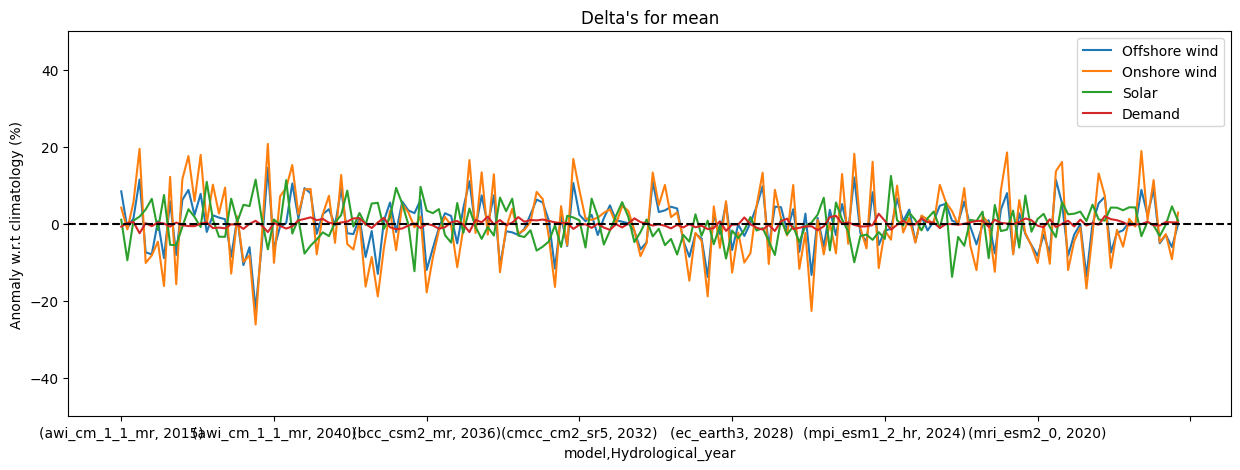

In [5]:
# NOTE: CDD is out of bounds for these plotting ylims.
plt.figure(figsize=(15, 5))
yearly_mean_anom_norm["NL_OFF_prod"].plot(label="Offshore wind")
yearly_mean_anom_norm["NL_ON_prod"].plot(label="Onshore wind")
yearly_mean_anom_norm["NL_SOLAR_prod"].plot(label="Solar")
yearly_mean_anom_norm["NL_Demand"].plot(label="Demand")
plt.axhline(y=0, c="k", linestyle="--")
# yearly_mean_anom_norm["CDD"].plot(label="CDD")
# yearly_mean_anom_norm["HDD"].plot(label="HDD")

plt.legend()
plt.ylabel("Anomaly w.r.t climatology (%)")
plt.title("Delta's for mean")
plt.ylim(-50, 50)

(-50.0, 50.0)

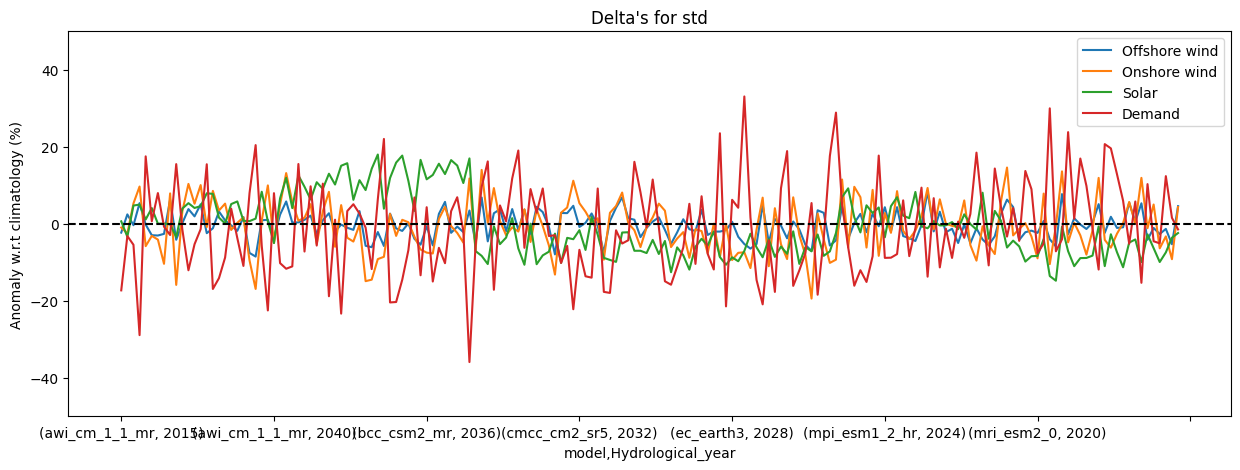

In [6]:
plt.figure(figsize=(15, 5))

yearly_std_anom_norm["NL_OFF_prod"].plot(label="Offshore wind")
yearly_std_anom_norm["NL_ON_prod"].plot(label="Onshore wind")
yearly_std_anom_norm["NL_SOLAR_prod"].plot(label="Solar")
yearly_std_anom_norm["NL_Demand"].plot(label="Demand")
plt.axhline(y=0, c="k", linestyle="--")

# yearly_std_anom_norm["CDD"].plot(label="CDD")
# yearly_std_anom_norm["HDD"].plot(label="HDD")


plt.legend(loc="upper right")
plt.ylabel("Anomaly w.r.t climatology (%)")
plt.title("Delta's for std")
plt.ylim(-50, 50)

# 2. Perform K-Medoids clustering

In [7]:
# standardize the data to mean = 0, std = 1
# TODO: Add HDD and CDD instead of TEMP
df_standardize = df_daily[["NL_OFF_prod", "NL_ON_prod", "NL_SOLAR_prod", "NL_Demand"]]

scaler = StandardScaler()
df_standardized = pd.DataFrame(
    scaler.fit_transform(df_standardize),
    columns=df_standardize.columns,
    index=df_daily.index,
)

In [8]:
def p95_day(s: pd.Series) -> float:
    """Return the 95th percentile of a Series."""
    return s.quantile(0.95)


def p5_day(s: pd.Series) -> float:
    """Return the 5th percentile of a Series."""
    return s.quantile(0.05)


def p95_week(s: pd.Series) -> float:
    """Return the 95th percentile week of a Series."""
    return s.rolling(window=7).mean().quantile(0.95)


def p5_week(s: pd.Series) -> float:
    """Return the 5th percentile week of a Series."""
    return s.rolling(window=7).mean().quantile(0.05)


# year = pd.Index(
#     df_nl_rolling.index.get_level_values("Date").year,
#     name="year",
# )
year = df_daily["Hydrological_year"]
# yearly_stats = df_standardized.groupby([pd.Grouper(level="model"), year]).agg(
#     ["mean", "var", p95_day, p5_day, p95_week, p5_week]
# )

yearly_stats = df_standardized.groupby([pd.Grouper(level="model"), year]).agg(
    ["mean", "var"]
)

yearly_stats.columns = [f"{col}_{stat}" for col, stat in yearly_stats.columns]

# scale the year‑level feature matrix
X = StandardScaler().fit_transform(yearly_stats)

In [9]:
# perform K-Medoids clustering

kmed = KMedoids(n_clusters=NUM_CLUSTERS).fit(X)
yearly_stats["cluster_med"] = kmed.labels_

pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X)  # (n_years, 2)
centers_pca = pca.transform(kmed.cluster_centers_)  # (k, 2)

# 3. Visualize clusters, using PCA-projection

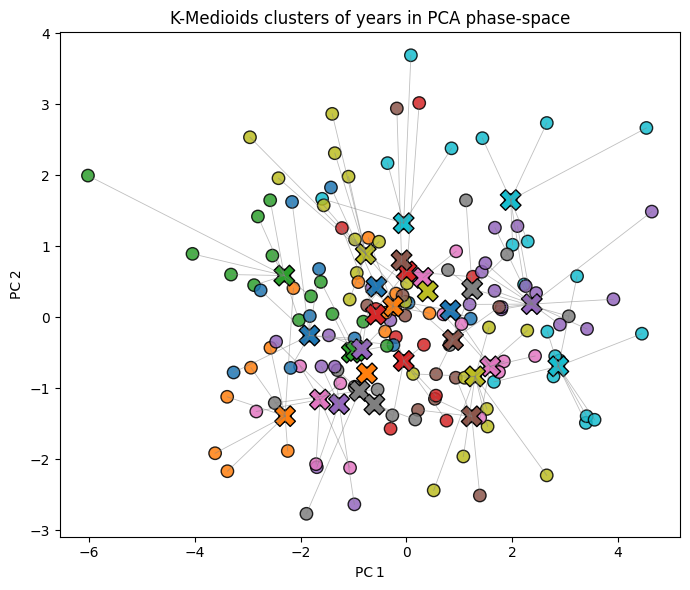

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))

# years as coloured dots
pts = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmed.labels_,
    cmap="tab10",
    s=80,
    alpha=0.85,
    edgecolor="k",
)

# lines to centroids (distance visualisation)
for i, (x, y) in enumerate(X_pca):
    cx, cy = centers_pca[kmed.labels_[i]]
    ax.plot([x, cx], [y, cy], lw=0.6, color="grey", alpha=0.5)

# centroids as large X‑markers
ax.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    c=range(len(centers_pca)),
    cmap="tab10",
    s=220,
    edgecolor="k",
)

ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_title("K-Medioids clusters of years in PCA phase‑space")
plt.tight_layout()
plt.show()

In [11]:
loadings = pd.DataFrame(
    pca.components_.T,  # shape (n_feats, n_components)
    index=yearly_stats.columns[:-1],  # drop 'cluster'
    columns=["PC1", "PC2"],
).round(3)

print("PCA loadings (coefficients):")
print(loadings)
print("\nExplained variance ratio:", pca.explained_variance_ratio_.round(3))

PCA loadings (coefficients):
                      PC1    PC2
NL_OFF_prod_mean    0.435 -0.232
NL_OFF_prod_var     0.356 -0.022
NL_ON_prod_mean     0.481 -0.199
NL_ON_prod_var      0.470 -0.050
NL_SOLAR_prod_mean -0.121  0.552
NL_SOLAR_prod_var   0.073  0.516
NL_Demand_mean     -0.277 -0.453
NL_Demand_var      -0.369 -0.357

Explained variance ratio: [0.455 0.187]


# 4. Analyze centroids

# temporary: analyse common years

In [ ]:
from itertools import chain
from collections import Counter

df_fullset = pd.read_csv(
    "/net/pc230050/nobackup/users/duinen/04_weather_year_selection/outputs/simulated_annealing/run_NL_20251024_1320/results_grid.csv",
    index_col=0,
)


def count_duplicates(df: pd.DataFrame) -> Counter:
    """Count duplicate modelyears in the selected years column."""
    lists = df["selected"].apply(eval)
    model_years_flat = list(chain.from_iterable(lists))
    return Counter(model_years_flat)


counts_full = count_duplicates(df_fullset)
# Calculate fraction of model_years in subset vs full
idx = sorted(counts_full.keys())
full = pd.Series({k: counts_full[k] for k in idx}, name="full")
full = full.sort_values(ascending=False)[:10]
ind_selections = full.index
yearly_mean_anom_norm.query("index in @ind_selections")

NL_OFF_prod  NL_ON_prod  NL_SOLAR_prod  \
model         Hydrological_year                                           
awi_cm_1_1_mr 2026                  8.845535   17.652599       3.826883   
              2030                  2.246342   10.209965       1.201691   
              2034                  1.537172    1.977881       0.583225   
bcc_csm2_mr   2015                  1.464791    2.480029       1.312398   
cmcc_cm2_sr5  2019                -10.871132  -12.541743       6.841392   
ec_earth3     2039                 -7.257122  -11.674009      -4.765979   
              2043                 -5.930796   -7.900853       6.814168   
mpi_esm1_2_hr 2033                  4.746606   10.157553      -1.105430   
              2038                 -0.754678   -5.684156       1.057339   
mri_esm2_0    2017                  2.786364    6.190628      -6.137383   

                                 NL_Demand  NL_Residual_load  DE_OFF_prod  \
model         Hydrological_year                                             
awi_cm_1_1_mr 2026               -0.545104       9063.302418     9.130225   
              2030               -1.095929       4212.739640     2.078243   
              2034               -0.186832       1478.621641     4.350158   
bcc_csm2_mr   2015                0.924747        647.995317    -0.281114   
cmcc_cm2_sr5  2019                1.003835      -5814.125439   -11.064165   
ec_earth3     2039               -1.005290      -6140.666741    -6.809571   
              2043               -0.626556       -969.119262    -6.035374   
mpi_esm1_2_hr 2033               -1.044712       4553.840083     6.878788   
              2038                0.434682      -1268.254369     1.846753   
mri_esm2_0    2017                0.491293       -481.089589    -2.008726   

                                 DE_ON_prod  DE_SOLAR_prod  DE_Demand  \
model         Hydrological_year                                         
awi_cm_1_1_mr 2026                20.450424      -1.898165  -0.272655   
              2030                11.002972       0.466133  -1.175979   
              2034                 4.634696      -0.050247  -0.012561   
bcc_csm2_mr   2015                -1.117146      -2.903570   0.789179   
cmcc_cm2_sr5  2019               -11.055130       8.262804   1.507639   
ec_earth3     2039                -5.588163      -5.035182  -1.313119   
              2043                -0.347990       3.562037  -0.869286   
mpi_esm1_2_hr 2033                12.103014       1.029267  -1.151233   
              2038                -4.593489       2.140853   1.158942   
mri_esm2_0    2017                -2.965760       2.748136   0.440973   

                                 DE_Residual_load  ...  BE_ON_prod  \
model         Hydrological_year                    ...               
awi_cm_1_1_mr 2026                    -130.894069  ...   21.362632   
              2030                     -76.052401  ...   10.285670   
              2034                     -53.385919  ...    3.795497   
bcc_csm2_mr   2015                      44.152019  ...    4.307541   
cmcc_cm2_sr5  2019                     102.364692  ...  -14.056674   
ec_earth3     2039                      90.712753  ...   -9.406810   
              2043                      13.373952  ...   -6.215350   
mpi_esm1_2_hr 2033                    -128.621618  ...   13.953601   
              2038                       1.783745  ...   -8.332730   
mri_esm2_0    2017                      14.969890  ...    5.247702   

                                 BE_SOLAR_prod  BE_Demand  BE_Residual_load  \
model         Hydrological_year                                               
awi_cm_1_1_mr 2026                   -1.097791  -0.312964       -176.855483   
              2030                   -0.640025  -1.085606        -88.970101   
              2034                    0.059781  -0.678522          2.393661   
bcc_csm2_mr   2015                   -2.425484   0.897927        -28.783650   
cmcc_cm2_sr5  2

## cont.

In [15]:
indices = kmed.medoid_indices_
centroid_years = yearly_mean_anom_norm.iloc[indices].copy()
centroid_years["count"] = (
    yearly_stats["cluster_med"].value_counts(sort=False).sort_index().values
)
centroid_years["cluster_id"] = range(30)
centroid_years_to_save = centroid_years.reset_index().set_index("cluster_id")

fname_centroids = os.path.join(
    BASE_OUTPUT, f"centroids/centroid_years_load_{NUM_CLUSTERS}yr.csv"
)
centroid_years_to_save.to_csv(fname_centroids)
centroid_years_to_save

,model,Hydrological_year,NL_OFF_prod,NL_ON_prod,NL_SOLAR_prod,NL_Demand,NL_Residual_load,DE_OFF_prod,DE_ON_prod,DE_SOLAR_prod,...,BE_SOLAR_prod,BE_Demand,BE_Residual_load,FR_OFF_prod,FR_ON_prod,FR_SOLAR_prod,FR_Demand,FR_Residual_load,Calendar_year,count
cluster_id,,,,,,,,,,,,,,,,,,,,,
0,cmcc_cm2_sr5,2020,-1.891402,-1.046465,3.316112,-0.325935,464.869583,0.122763,9.025483,7.764658,...,7.382752,-0.304451,-8.995008,-15.791022,-8.103204,7.356843,0.128740,-174.460416,-0.443542,2
1,ec_earth3,2028,-6.782643,-12.638555,-1.726607,-0.182619,-5749.211687,-5.456012,-13.367891,-1.063585,...,-1.389574,-0.278925,152.983476,-8.466334,-10.535859,-0.187811,-0.453776,-161.494241,-0.049307,9
2,awi_cm_1_1_mr,2017,1.477977,5.646771,0.862575,0.504418,1383.486317,0.567897,3.612003,1.602177,...,1.051005,0.606504,-47.004996,3.192953,4.285559,-1.189734,0.732345,26.285141,-0.591380,3
3,ec_earth3,2026,-2.639786,-6.216775,-0.432726,0.693864,-3123.973053,-6.863245,-8.818965,3.377546,...,-2.132105,0.570145,67.582579,0.807372,-1.541946,-1.161168,-0.138736,-6.304585,-0.147866,8
4,mri_esm2_0,2038,2.249608,0.989767,0.523542,0.565463,899.298142,2.117408,3.964610,-1.261836,...,-1.323859,0.390839,28.830194,-2.023539,1.691844,-0.656551,-0.387289,-19.886065,0.443486,1
5,mri_esm2_0,2036,-0.490372,-0.674916,4.289975,-0.102618,1363.618989,-2.558539,-4.728970,3.975795,...,3.681230,-0.086052,10.852648,-9.943196,-8.941549,1.275586,-0.162821,-165.777219,0.344927,8
6,awi_cm_1_1_mr,2021,0.693203,-4.598085,-1.567580,0.369704,-1291.790682,-0.078535,-10.723828,-4.437277,...,-2.112677,0.523700,57.416170,0.248313,-3.466427,-4.100895,0.756179,-93.532089,-0.394263,3
7,mri_esm2_0,2034,-1.656858,-5.895686,3.560380,0.432751,-816.958298,2.283587,-0.882743,2.232928,...,4.748813,0.528336,163.013678,-17.186719,-19.378180,7.160298,0.733538,-266.852990,0.246369,3
8,mri_esm2_0,2042,-6.000082,-9.164178,4.566717,0.409248,-3094.198090,-6.553393,-9.819846,6.083855,...,3.676374,0.570310,95.881100,-0.632783,-5.026747,1.481738,0.924483,-40.568166,0.640604,10


In [15]:
yearly_mean_anom_std_scaled.iloc[indices]

NL_OFF_prod  NL_ON_prod  NL_SOLAR_prod  \
model         Hydrological_year                                           
cmcc_cm2_sr5  2020                 -0.312916   -0.112809       0.718464   
ec_earth3     2028                 -1.122129   -1.362436      -0.374084   
awi_cm_1_1_mr 2017                  0.244518    0.608722       0.186884   
ec_earth3     2026                 -0.436730   -0.670168      -0.093754   
mri_esm2_0    2038                  0.372178    0.106697       0.113430   
              2036                 -0.081128   -0.072756       0.929459   
awi_cm_1_1_mr 2021                  0.114684   -0.495673      -0.339630   
mri_esm2_0    2034                 -0.274113   -0.635555       0.771386   
              2042                 -0.992661   -0.987898       0.989418   
mpi_esm1_2_hr 2041                  0.160086    0.010033      -1.927002   
              2032                  0.119218   -0.000969       0.700354   
              2028                  0.616689    0.165018       0.634838   
              2033                  0.785285    1.094984      -0.239501   
              2027                  0.129026   -0.240535      -0.088056   
mri_esm2_0    2027                 -0.012254   -0.100876       0.695638   
ec_earth3     2022                 -0.421493   -0.251147       0.543350   
cmcc_cm2_sr5  2029                  0.340020    0.497915      -1.296977   
mri_esm2_0    2043                 -0.014387    0.318818       0.181404   
              2019                 -0.910888   -0.611981      -0.438123   
awi_cm_1_1_mr 2034                  0.254312    0.213215       0.126361   
ec_earth3     2017                  0.582701    1.092471      -1.192338   
cmcc_cm2_sr5  2024                  0.411194    0.060590      -0.353227   
mri_esm2_0    2035                  0.083638    0.140267       0.935364   
cmcc_cm2_sr5  2027                  0.143585   -0.372347      -0.988188   
mpi_esm1_2_hr 2034                  0.865168    0.603543       1.196583   
bcc_csm2_mr   2021                 -0.056974   -0.528211       0.091977   
mpi_esm1_2_hr 2043                  0.617199    0.948519      -0.403453   
awi_cm_1_1_mr 2038                 -0.923116   -0.369748       0.287730   
mpi_esm1_2_hr 2022                  1.362632    1.741127      -0.895019   
bcc_csm2_mr   2030                  0.920959    0.372297       0.379746   

                                 NL_Demand  NL_Residual_load  DE_OFF_prod  \
model         Hydrological_year                                             
cmcc_cm2_sr5  2020               -0.354905         -0.103454     0.019407   
ec_earth3     2028               -0.198851          1.279450    -0.862503   
awi_cm_1_1_mr 2017                0.549252         -0.307886     0.089775   
ec_earth3     2026                0.755538          0.695220    -1.084963   
mri_esm2_0    2038                0.615724         -0.200133     0.334727   
              2036               -0.111739         -0.303465    -0.404462   
awi_cm_1_1_mr 2021                0.402565          0.287480    -0.012415   
mri_esm2_0    2034                0.471216          0.181809     0.360997   
              2042                0.445624          0.688594    -1.035981   
mpi_esm1_2_hr 2041               -0.833549          0.454011     0.078208   
              2032                0.400270         -0.266130     0.335517   
              2028               -0.219364         -0.759848     0.995936   
              2033               -1.137570         -1.013428     1.087420   
              2027                0.881540          0.203991     0.566224   
mri_esm2_0    2027                1.230825          0.029697     0.062126   
ec_earth3     2022               -0.949629         -0.044977    -0.472688   
cmcc_cm2_sr5  2029                0.220161          0.162213     0.239994   
mri_esm2_0    2043                0.388235         -0.075332    -0.251616   
              2019                1.055907          1.195616    -0.948563   
awi_cm_1_1_mr 2

In [37]:
clim_means

NL_OFF_prod          214.371549
NL_ON_prod            62.329575
NL_SOLAR_prod        158.598960
NL_Demand            434.876342
NL_Residual_load      -0.423742
DE_OFF_prod          203.917520
DE_ON_prod            54.495155
DE_SOLAR_prod        162.861947
DE_Demand            442.572704
DE_Residual_load      21.298082
BE_OFF_prod          189.837213
BE_ON_prod            64.277617
BE_SOLAR_prod        161.735296
BE_Demand            436.269113
BE_Residual_load      20.418987
FR_OFF_prod          200.697505
FR_ON_prod            57.576282
FR_SOLAR_prod        186.793365
FR_Demand            431.785344
FR_Residual_load     -13.281808
Calendar_year       2029.247144
dtype: float64

In [16]:
# make rolling mean for plotting, but keep Hydrological_year column
df_rolling = df_daily.rolling(window=7).mean()
df_rolling["Hydrological_year"] = df_daily["Hydrological_year"]

/usr/people/duinen/04_weather_year_selection/src/cluster_weather_years/functions.py:251: RuntimeWarning: Mean of empty slice
  clim_per_cluster[i] = np.nanmean(cluster_data, axis=0)


IndexError: tuple index out of range

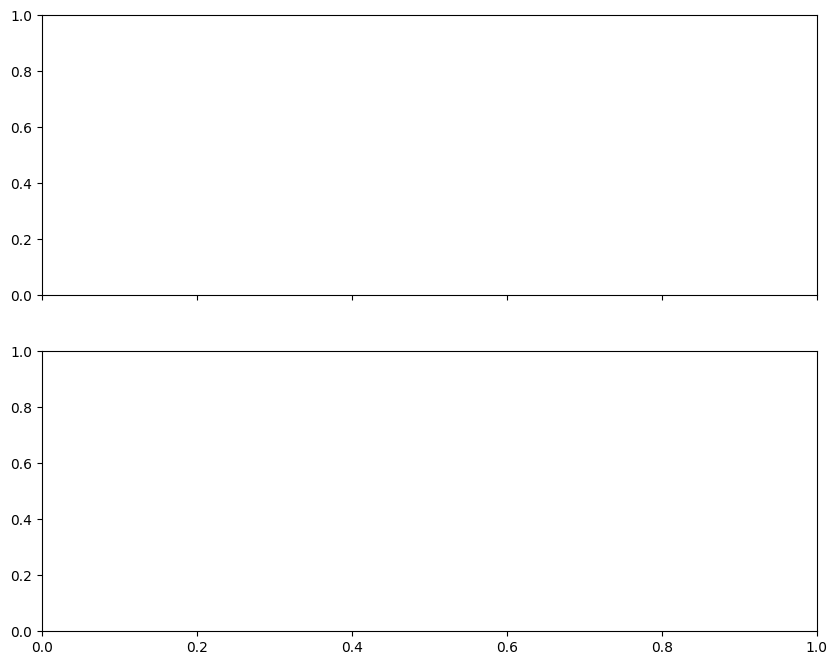

In [17]:
plot_clim_per_cluster(
    df_rolling, yearly_stats, centroid_years, "NL_OFF_prod", num_clusters=NUM_CLUSTERS
)

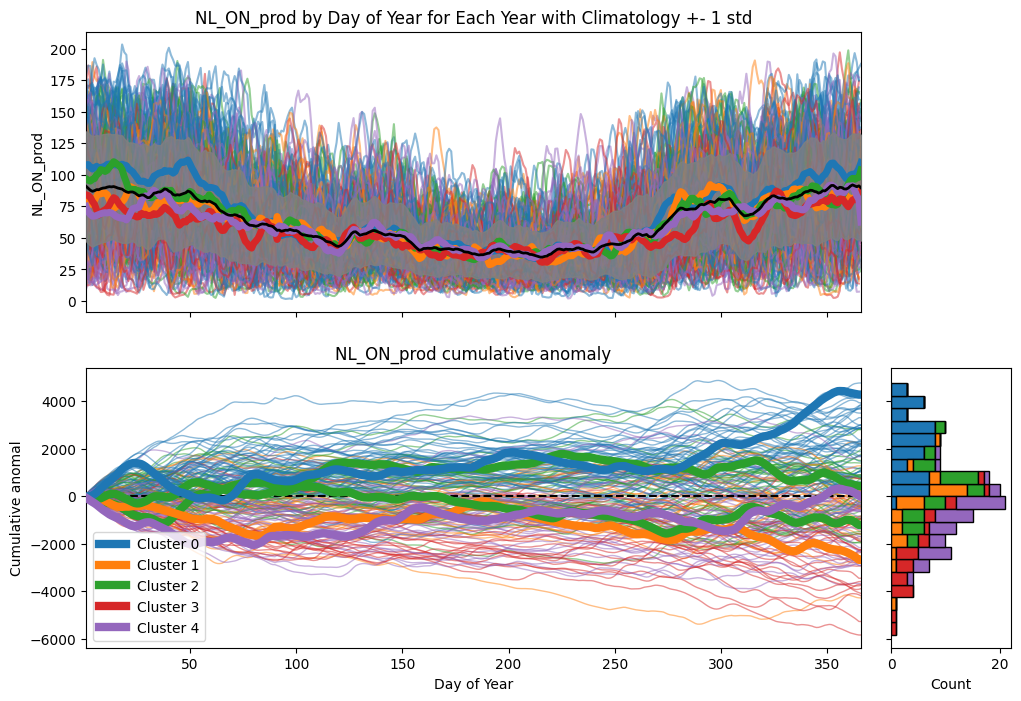

In [24]:
plot_clim_per_cluster(
    df_rolling, yearly_stats, centroid_years, "NL_ON_prod", num_clusters=NUM_CLUSTERS
)

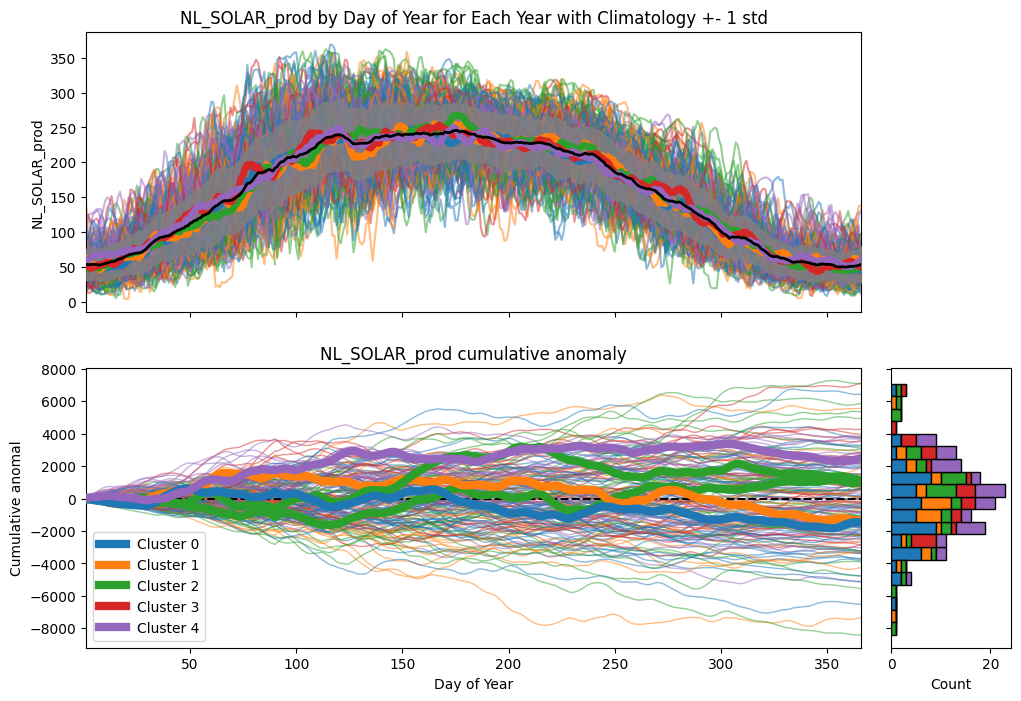

In [25]:
plot_clim_per_cluster(
    df_rolling, yearly_stats, centroid_years, "NL_SOLAR_prod", num_clusters=NUM_CLUSTERS
)

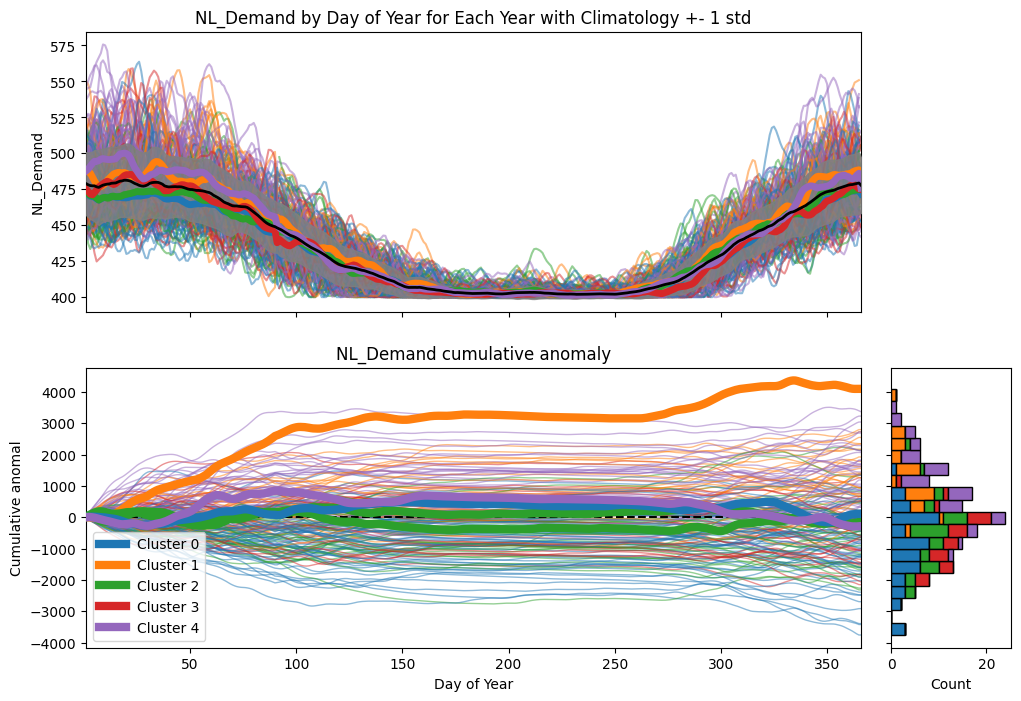

In [26]:
plot_clim_per_cluster(
    df_rolling, yearly_stats, centroid_years, "NL_Demand", num_clusters=NUM_CLUSTERS
)